# Capstone · Stage 4 — A working reconciliation engine for Kestrel Bay Capital

*Skill from Part 4: find the bottleneck in a workflow and automate it. Part 4 described a reconciliation engine; this stage builds one.*

The client's fourth objective is *faster, more reliable trade reporting*. The bank's order management system (OMS) and the
custodian each hold a record of the year's 3,000 trades. The generator planted 270 real breaks in the custodian file
(wrong price, wrong quantity, wrong date, missing trade, duplicate booking) and 30 decoys: the same trade ID written
differently (`" kb-000123"` instead of `"KB-000123"`), which is **not** a break.

1. Load both files
2. Run two engines: a naive spreadsheet-style lookup, and the rule-based engine in `src/reconciliation.py`
3. Score both against the ground truth (the engines never see it) → `figures/s4_table_scores.tex`, `figures/s4_fig_scores.pdf`
4. Why the naive lookup fails → `figures/s4_table_naive_errors.tex`
5. How sensitive the engine is to its one setting, the price tolerance → `figures/s4_fig_tolerance.pdf`
6. The exception report an analyst would work from → `outputs/exceptions_report.csv`, `figures/s4_table_exceptions.tex`
7. Operational impact → `figures/s4_table_workload.tex`
8. Limits and key findings

## 1. Load both files

In [1]:
import sys
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.insert(0, "src")
from reconciliation import BREAK_TYPES, exception_report, naive_reconcile, reconcile

DATA_DIR, FIGURES_DIR, OUTPUTS_DIR = Path("data"), Path("figures"), Path("outputs")
FIGURES_DIR.mkdir(exist_ok=True)
OUTPUTS_DIR.mkdir(exist_ok=True)

oms_trades = pd.read_csv(DATA_DIR / "trades_oms.csv")
custodian_trades = pd.read_csv(DATA_DIR / "trades_custodian.csv")
ground_truth = pd.read_csv(DATA_DIR / "breaks_truth.csv")          # used for scoring only
# An ID-format difference is the same trade, so the correct answer for it is "match"
ground_truth["expected_status"] = ground_truth["break_type"].replace({"none": "match", "id_format": "match"})

# Two-series palette (validated: lightness, chroma, colour-blind separation, normal-vision floor)
NAIVE_COLOR, ENGINE_COLOR = "#D9822B", "#2A55B0"
TEXT_COLOR, MUTED_COLOR = "#222222", "#666666"
plt.rcParams.update({"font.size": 9.5, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": "#BBBBBB", "xtick.color": MUTED_COLOR, "ytick.color": MUTED_COLOR})

print(f"OMS: {len(oms_trades):,} trades | custodian: {len(custodian_trades):,} bookings")
ground_truth["break_type"].value_counts().rename("Planted (ground truth)").to_frame()

OMS: 3,000 trades | custodian: 2,985 bookings


,Planted (ground truth)
break_type,
none,2700
price,120
quantity,60
settle_date,45
missing,30
id_format,30
duplicate,15


## 2. Two engines

| | Naive lookup | Rule-based engine |
|---|---|---|
| Trade ID | exact text match | spaces removed, upper case |
| Duplicates | takes the first booking, never notices | counts bookings per trade; more than one is a break |
| Price | must be identical | difference up to 10 bp is rounding, not a break |
| Result | first mismatch found | one break type per trade, by severity: missing → duplicate → quantity → price → date |

In [2]:
start = time.perf_counter()
naive_result = naive_reconcile(oms_trades, custodian_trades)
naive_seconds = time.perf_counter() - start

start = time.perf_counter()
engine_result = reconcile(oms_trades, custodian_trades, price_tolerance_bp=10)
engine_seconds = time.perf_counter() - start
print(f"Naive lookup: {naive_seconds:.2f} s | rule-based engine: {engine_seconds:.2f} s for {len(oms_trades):,} trades")

Naive lookup: 0.02 s | rule-based engine: 0.02 s for 3,000 trades


## 3. Score against the ground truth

- **Breaks found** (recall): share of the 270 real breaks that were flagged.
- **Precision**: share of flagged trades that really are breaks. Low precision = analysts chase false alarms.
- **Correct break type**: among real breaks found, share labelled with the right type, so the right person fixes it.

In [3]:
def score(result):
    scored = result[["trade_id", "status"]].merge(ground_truth, on="trade_id")
    flagged = scored["status"] != "match"
    real_break = scored["expected_status"] != "match"
    true_alarms = (flagged & real_break).sum()
    return {
        "Trades flagged": int(flagged.sum()),
        "Real breaks found": int(true_alarms),
        "Real breaks missed": int((~flagged & real_break).sum()),
        "False alarms": int((flagged & ~real_break).sum()),
        "Recall (%)": 100 * true_alarms / real_break.sum(),
        "Precision (%)": 100 * true_alarms / flagged.sum(),
        "Correct break type (%)": 100 * (scored.loc[flagged & real_break, "status"]
                                         == scored.loc[flagged & real_break, "expected_status"]).mean(),
        "Every trade classified correctly (%)": 100 * (scored["status"] == scored["expected_status"]).mean(),
    }


scores = pd.DataFrame({"Naive lookup": score(naive_result), "Rule-based engine": score(engine_result)})
scores.round(1)

,Naive lookup,Rule-based engine
Trades flagged,1372.0,270.0
Real breaks found,260.0,270.0
Real breaks missed,10.0,0.0
False alarms,1112.0,0.0
Recall (%),96.3,100.0
Precision (%),19.0,100.0
Correct break type (%),80.8,100.0
Every trade classified correctly (%),60.9,100.0


In [4]:
table_lines = [r"\begin{tabular}{@{}lrr@{}}", r"\toprule",
               r"\textbf{Measure (3{,}000 trades, 270 real breaks)} & \textbf{Naive lookup} & \textbf{Rule-based engine} \\", r"\midrule"]
for measure, row in scores.iterrows():
    is_percentage = "(%)" in measure
    cells = [f"{value:.1f}" + r"\%" if is_percentage else f"{value:,.0f}" for value in row]
    table_lines.append(measure.replace(" (%)", "").replace("%", r"\%") + " & " + " & ".join(cells) + r" \\")
table_lines += [r"\bottomrule", r"\end{tabular}"]
(FIGURES_DIR / "s4_table_scores.tex").write_text("\n".join(table_lines))
print("\n".join(table_lines))

\begin{tabular}{@{}lrr@{}}
\toprule
\textbf{Measure (3{,}000 trades, 270 real breaks)} & \textbf{Naive lookup} & \textbf{Rule-based engine} \\
\midrule
Trades flagged & 1,372 & 270 \\
Real breaks found & 260 & 270 \\
Real breaks missed & 10 & 0 \\
False alarms & 1,112 & 0 \\
Recall & 96.3\% & 100.0\% \\
Precision & 19.0\% & 100.0\% \\
Correct break type & 80.8\% & 100.0\% \\
Every trade classified correctly & 60.9\% & 100.0\% \\
\bottomrule
\end{tabular}


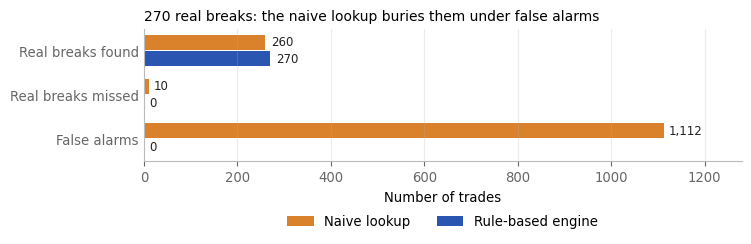

In [5]:
measures = ["Real breaks found", "Real breaks missed", "False alarms"]
fig, ax = plt.subplots(figsize=(7.6, 2.8))
rows = np.arange(len(measures))
BAR_HEIGHT = 0.38
for engine_name, offset, color in [("Naive lookup", -BAR_HEIGHT / 2, NAIVE_COLOR),
                                   ("Rule-based engine", BAR_HEIGHT / 2, ENGINE_COLOR)]:
    counts = scores.loc[measures, engine_name]
    bars = ax.barh(rows + offset, counts, height=BAR_HEIGHT - 0.04, color=color, label=engine_name)
    for bar, count in zip(bars, counts):
        ax.text(count + 12, bar.get_y() + bar.get_height() / 2, f"{count:,.0f}", va="center", fontsize=8.5,
                color=TEXT_COLOR)
ax.set_yticks(rows, measures)
ax.invert_yaxis()
ax.tick_params(axis="y", length=0)
ax.set_xlabel("Number of trades")
ax.set_xlim(0, scores.loc[measures].to_numpy().max() * 1.15)
ax.grid(axis="x", alpha=0.25)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.32), ncol=2, frameon=False)
ax.set_title("270 real breaks: the naive lookup buries them under false alarms", loc="left", fontsize=10)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "s4_fig_scores.pdf", bbox_inches="tight")
plt.show()

## 4. Why the naive lookup fails

In [6]:
naive_scored = naive_result.merge(ground_truth, on="trade_id")
naive_scored["price_gap"] = (custodian_trades.drop_duplicates("trade_id").set_index("trade_id")["price"]
                             .reindex(naive_scored["trade_id"]).to_numpy() - oms_trades.set_index("trade_id")
                             .loc[naive_scored["trade_id"], "price"].to_numpy())
error_causes = {
    "Price rounding in the 3rd decimal flagged as a price break":
        int(((naive_scored["status"] == "price") & (naive_scored["expected_status"] == "match")
             & (naive_scored["break_type"] != "id_format")).sum()),
    "Same trade, ID written differently, flagged as missing":
        int(((naive_scored["status"] == "missing") & (naive_scored["break_type"] == "id_format")).sum()),
    "Duplicate booking not detected":
        int(((naive_scored["expected_status"] == "duplicate") & (naive_scored["status"] != "duplicate")).sum()),
    "Real break labelled with the wrong type (rounding noise hides the real issue)":
        int(((naive_scored["status"] != naive_scored["expected_status"]) & (naive_scored["expected_status"] != "match")
             & (naive_scored["expected_status"] != "duplicate")).sum()),
}
naive_errors = pd.Series(error_causes, name="Trades")
display(naive_errors.to_frame())

table_lines = [r"\begin{tabular}{@{}lr@{}}", r"\toprule", r"\textbf{Cause} & \textbf{Trades} \\", r"\midrule"]
table_lines += [f"{cause} & {count:,} " + r"\\" for cause, count in naive_errors.items()]
table_lines += [r"\bottomrule", r"\end{tabular}"]
(FIGURES_DIR / "s4_table_naive_errors.tex").write_text("\n".join(table_lines))

,Trades
Price rounding in the 3rd decimal flagged as a price break,1082
"Same trade, ID written differently, flagged as missing",30
Duplicate booking not detected,15
Real break labelled with the wrong type (rounding noise hides the real issue),45


363

## 5. Sensitivity to the price tolerance

The engine has one setting. Too tight and rounding becomes false alarms; too loose and small real price errors slip through.
The planted price breaks are 1% or 10% (100 or 1,000 bp); the rounding noise is at most 0.004 on prices of 20 to 400.

In [7]:
tolerances_bp = [0, 0.5, 1, 2, 3, 5, 10, 25, 50, 75, 100, 150, 200, 500]
sweep = pd.DataFrame({tolerance: score(reconcile(oms_trades, custodian_trades, price_tolerance_bp=tolerance))
                      for tolerance in tolerances_bp}).T
sweep.index.name = "Price tolerance (bp)"
perfect = sweep.index[(sweep["Recall (%)"] == 100) & (sweep["Precision (%)"] == 100)]
print(f"Perfect precision and recall for tolerances from {perfect.min()} to {perfect.max()} bp (tested values)")
sweep[["Trades flagged", "False alarms", "Real breaks missed", "Precision (%)", "Recall (%)"]].round(1)

Perfect precision and recall for tolerances from 2.0 to 75.0 bp (tested values)


,Trades flagged,False alarms,Real breaks missed,Precision (%),Recall (%)
Price tolerance (bp),,,,,
0.0,1370.0,1100.0,0.0,19.7,100.0
0.5,482.0,212.0,0.0,56.0,100.0
1.0,482.0,212.0,0.0,56.0,100.0
2.0,270.0,0.0,0.0,100.0,100.0
3.0,270.0,0.0,0.0,100.0,100.0
5.0,270.0,0.0,0.0,100.0,100.0
10.0,270.0,0.0,0.0,100.0,100.0
25.0,270.0,0.0,0.0,100.0,100.0
50.0,270.0,0.0,0.0,100.0,100.0


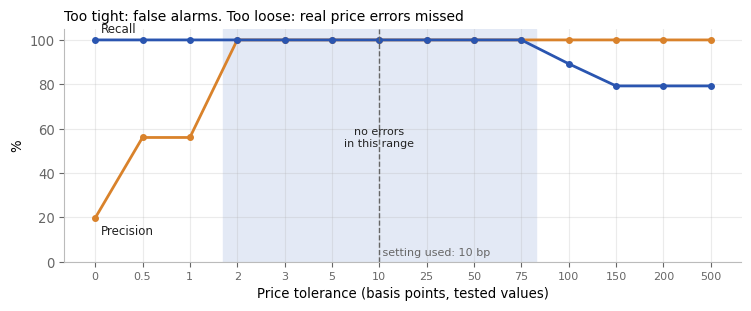

In [8]:
# Tested tolerances are evenly spaced on the x-axis (their values are on the tick labels)
positions = np.arange(len(tolerances_bp))
perfect_positions = [tolerances_bp.index(t) for t in perfect]
fig, ax = plt.subplots(figsize=(7.6, 3.2))
ax.axvspan(min(perfect_positions) - 0.3, max(perfect_positions) + 0.3, color="#E3E9F5", zorder=0)
ax.text(np.mean(perfect_positions), 52, "no errors\nin this range", ha="center", fontsize=8, color=TEXT_COLOR)
for column, color, label_offset in [("Precision (%)", NAIVE_COLOR, -12), ("Recall (%)", ENGINE_COLOR, 5)]:
    ax.plot(positions, sweep[column], marker="o", ms=4, lw=2, color=color)
    ax.annotate(column.replace(" (%)", ""), (positions[0], sweep[column].iloc[0]), xytext=(4, label_offset),
                textcoords="offset points", fontsize=8.5, color=TEXT_COLOR)
setting_position = tolerances_bp.index(10)
ax.axvline(setting_position, color=MUTED_COLOR, ls="--", lw=1)
ax.text(setting_position, 3, " setting used: 10 bp", fontsize=8, color=MUTED_COLOR)
ax.set_xticks(positions, [f"{t:g}" for t in tolerances_bp], fontsize=8)
ax.set_xlabel("Price tolerance (basis points, tested values)")
ax.set_ylabel("%")
ax.set_ylim(0, 105)
ax.grid(alpha=0.25)
ax.set_title("Too tight: false alarms. Too loose: real price errors missed", loc="left", fontsize=10)
fig.tight_layout()
fig.savefig(FIGURES_DIR / "s4_fig_tolerance.pdf", bbox_inches="tight")
plt.show()

## 6. The exception report

In [9]:
exceptions = exception_report(engine_result)
exceptions.to_csv(OUTPUTS_DIR / "exceptions_report.csv", index=False)
print(f"{len(exceptions)} exceptions written to outputs/exceptions_report.csv")
display(pd.crosstab(exceptions["status"], exceptions["priority"]).reindex(columns=["High", "Medium", "Low"], fill_value=0))

top_exceptions = exceptions.head(8)


def describe_gap(row):
    if row["status"] == "price":
        return f"{row['oms_price']:.2f} vs {row['custodian_price']:.2f} ({row['price_gap_bp']:+,.0f} bp)"
    if row["status"] == "quantity":
        return f"{row['oms_quantity']:,.0f} vs {row['custodian_quantity']:,.0f}"
    if row["status"] == "settle_date":
        return f"{row['oms_date']} vs {row['custodian_date']}"
    if row["status"] == "missing":
        return "no custodian booking"
    return "booked twice"


table_lines = [r"\begin{tabular}{@{}lllrll@{}}", r"\toprule",
               r"\textbf{Trade} & \textbf{Break} & \textbf{Priority} & \textbf{Notional} & \textbf{OMS vs custodian} & \textbf{Ticker} \\",
               r"\midrule"]
for _, row in top_exceptions.iterrows():
    table_lines.append(f"{row['trade_id']} & {row['status'].replace('_', ' ')} & {row['priority']} & "
                       f"\\${row['notional_usd'] / 1e3:,.0f}k & {describe_gap(row)} & {row['ticker']} " + r"\\")
table_lines += [r"\bottomrule", r"\end{tabular}"]
(FIGURES_DIR / "s4_table_exceptions.tex").write_text("\n".join(table_lines))
top_exceptions[["trade_id", "status", "priority", "notional_usd", "ticker", "action"]]

270 exceptions written to outputs/exceptions_report.csv


priority,High,Medium,Low
status,,,
duplicate,15,0,0
missing,30,0,0
price,54,56,10
quantity,25,32,3
settle_date,21,20,4


,trade_id,status,priority,notional_usd,ticker,action
871,KB-000552,price,High,3729561.5,SOLR,Check the execution price with the broker; ask...
1131,KB-002621,settle_date,High,3693176.0,MEDA,Check the trade date / settlement instructions...
2545,KB-002161,price,High,3571708.0,MEDA,Check the execution price with the broker; ask...
2025,KB-000677,price,High,3476467.0,MEDA,Check the execution price with the broker; ask...
476,KB-002338,settle_date,High,3361244.0,MEDA,Check the trade date / settlement instructions...
508,KB-000060,price,High,3329010.0,RETX,Check the execution price with the broker; ask...
115,KB-002248,missing,High,3272187.5,MEDA,Custodian has no record: send the trade detail...
71,KB-000012,price,High,3236604.0,MEDA,Check the execution price with the broker; ask...


## 7. Operational impact

Assumptions: today an analyst validates **every** trade by hand, about 20 minutes each (Part 4's client profile);
with any automated tool, the analyst only reviews flagged trades, about 10 minutes each.

In [10]:
MANUAL_MINUTES_PER_TRADE, REVIEW_MINUTES_PER_FLAG = 20, 10
workload = pd.DataFrame({
    "Trades reviewed by hand": [len(oms_trades), scores.loc["Trades flagged", "Naive lookup"],
                                scores.loc["Trades flagged", "Rule-based engine"]],
    "Minutes per trade": [MANUAL_MINUTES_PER_TRADE, REVIEW_MINUTES_PER_FLAG, REVIEW_MINUTES_PER_FLAG],
    "Real breaks missed": [np.nan, scores.loc["Real breaks missed", "Naive lookup"],
                           scores.loc["Real breaks missed", "Rule-based engine"]],
}, index=["Manual check of every trade", "Naive lookup + review", "Rule-based engine + review"])
workload["Analyst hours per year"] = workload["Trades reviewed by hand"] * workload["Minutes per trade"] / 60
workload["Hours saved vs manual (%)"] = 100 * (1 - workload["Analyst hours per year"]
                                               / workload.loc["Manual check of every trade", "Analyst hours per year"])
display(workload.round(0))

table_lines = [r"\begin{tabular}{@{}lrrrr@{}}", r"\toprule",
               r"\textbf{Process} & \textbf{Trades reviewed} & \textbf{Analyst hours} & \textbf{Saved} & \textbf{Breaks missed} \\", r"\midrule"]
for process, row in workload.iterrows():
    missed = "not measured" if np.isnan(row["Real breaks missed"]) else f"{row['Real breaks missed']:.0f}"
    saved = "---" if row["Hours saved vs manual (%)"] == 0 else f"{row['Hours saved vs manual (%)']:.0f}" + r"\%"
    table_lines.append(f"{process} & {row['Trades reviewed by hand']:,.0f} & {row['Analyst hours per year']:,.0f} & "
                       f"{saved} & {missed} " + r"\\")
table_lines += [r"\bottomrule", r"\end{tabular}"]
(FIGURES_DIR / "s4_table_workload.tex").write_text("\n".join(table_lines))

,Trades reviewed by hand,Minutes per trade,Real breaks missed,Analyst hours per year,Hours saved vs manual (%)
Manual check of every trade,3000.0,20,NaN,1000.0,0.0
Naive lookup + review,1372.0,10,10.0,229.0,77.0
Rule-based engine + review,270.0,10,0.0,45.0,96.0


357

## 8. Limits and key findings

**Why 100% is not the headline.** The planted breaks are cleanly separated from the noise (real price errors of 1–10%,
rounding of a fraction of a basis point), so a well-built engine can catch all of them. Real reconciliations are messier:
partial fills, corporate actions, FX conversions, trades split across accounts, and IDs that differ more than by case.
The useful results are the *comparison* with the naive lookup, the safe range for the tolerance, and the workload saved.

In [11]:
naive_scores, engine_scores = scores["Naive lookup"], scores["Rule-based engine"]
findings = [
    f"Naive lookup: flagged {naive_scores['Trades flagged']:,.0f} trades for 270 real breaks "
    f"(precision {naive_scores['Precision (%)']:.0f}%), with {naive_scores['False alarms']:,.0f} false alarms "
    f"and {naive_scores['Real breaks missed']:.0f} breaks missed.",
    f"Rule-based engine: flagged {engine_scores['Trades flagged']:,.0f}; recall {engine_scores['Recall (%)']:.0f}%, "
    f"precision {engine_scores['Precision (%)']:.0f}%, correct break type {engine_scores['Correct break type (%)']:.0f}%, "
    f"in {engine_seconds:.2f} s.",
    "Main naive failure: " + max(error_causes, key=error_causes.get).lower()
    + f" ({max(error_causes.values()):,} trades).",
    f"The engine stays error-free for price tolerances between {perfect.min():g} and {perfect.max():g} bp; "
    "10 bp sits safely inside.",
    f"Analyst time: {workload.iloc[0]['Analyst hours per year']:,.0f} h a year by hand -> "
    f"{workload.iloc[2]['Analyst hours per year']:,.0f} h with the engine "
    f"({workload.iloc[2]['Hours saved vs manual (%)']:.0f}% saved), vs {workload.iloc[1]['Analyst hours per year']:,.0f} h with the naive lookup.",
]
for finding in findings:
    print("-", finding)
(FIGURES_DIR / "s4_findings.txt").write_text("\n".join(findings))

- Naive lookup: flagged 1,372 trades for 270 real breaks (precision 19%), with 1,112 false alarms and 10 breaks missed.
- Rule-based engine: flagged 270; recall 100%, precision 100%, correct break type 100%, in 0.02 s.
- Main naive failure: price rounding in the 3rd decimal flagged as a price break (1,082 trades).
- The engine stays error-free for price tolerances between 2 and 75 bp; 10 bp sits safely inside.
- Analyst time: 1,000 h a year by hand -> 45 h with the engine (96% saved), vs 229 h with the naive lookup.


511